In [2]:
display("text/html", "<style>.container { width:100% !important; }</style>")

In [3]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, StatsBase

In [4]:
Plots.theme(:dao)

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [6]:
pwd()

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations"

In [7]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
read_data = filter(:nreads => !=(0), read_data)
# first split on classification
gd1 = groupby(read_data, :classification);

gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

classes = [gd_classes[i][1][!,:classification][2] for i in 1:length(gd_classes)]
classes = strip.(lowercase.(classes))
classes[10] = "marine hydrothermal vents"
classes[6] = "oral cavity"
classes[5] = "terrestrial soil"
classes[end] = "activated sludge"
classes

14-element Vector{SubString{String}}:
 "seawater"
 "oral"
 "gut"
 "vaginal"
 "terrestrial soil"
 "oral cavity"
 "feces"
 "skin"
 "glacier"
 "marine hydrothermal vents"
 "river"
 "lake"
 "environmental aquatic marine"
 "activated sludge"

In [8]:
cdata = DataFrame[]
for i in [1,2,3,4,5,6,8,9,12,13,14]
    t_data = CSV.read("./calibration_results_p0_fixed2/eco-calib-$(i).csv", DataFrame)
    push!(cdata, t_data)
end

In [9]:
cdata

11-element Vector{DataFrame}:
 10×3 DataFrame
 Row │ theta     gamma    fitness  
     │ Float64   Float64  Float64  
─────┼─────────────────────────────
   1 │ 0.697582  1.1302    5.28994
   2 │ 0.544401  1.01172   5.14817
   3 │ 0.59134   1.00869   4.05522
   4 │ 1.49568   1.32765  12.8014
   5 │ 0.600075  1.05914   4.78453
   6 │ 0.571768  1.04917   5.69756
   7 │ 0.619469  1.07371   4.27376
   8 │ 0.694804  1.05936   4.11326
   9 │ 0.766983  1.14237   2.48747
  10 │ 0.689025  1.1403    3.70591
 10×3 DataFrame
 Row │ theta       gamma     fitness 
     │ Float64     Float64   Float64 
─────┼───────────────────────────────
   1 │  0.0924504  1.00613   6.92446
   2 │ -0.367724   1.00248   6.98948
   3 │ -0.241099   1.02641   6.77657
   4 │ -0.537622   1.00918   7.38806
   5 │ -0.11696    1.01718   7.6826
   6 │ -0.0976402  0.979541  7.364
   7 │ -0.447773   0.981394  5.45259
   8 │ -0.317984   1.0089    5.14969
   9 │  0.0576005  0.984839  5.70181
  10 │  0.275056   1.04604   5.28778


In [10]:
cdata[1][!,:theta]

10-element Vector{Float64}:
 0.6975821944438831
 0.5444010427764875
 0.5913404292258653
 1.4956765945759418
 0.6000749160157254
 0.5717681730531489
 0.6194690980368854
 0.6948036153078935
 0.7669827735759325
 0.6890249868867928

In [11]:
cpal_plot =  [pal[i] for i in 0.0:1/length(cdata):1]

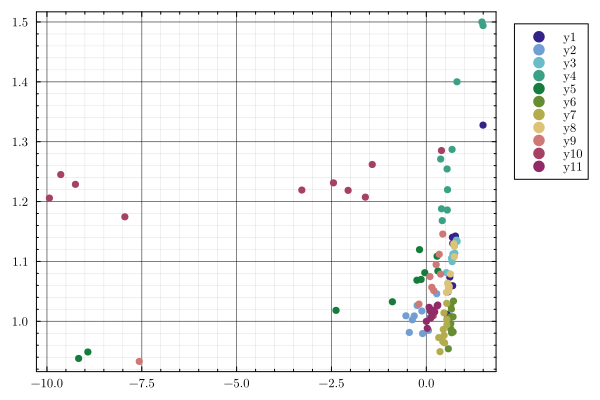

In [12]:
plot()
for i in 1:length(cdata)
    scatter!(cdata[i][!,:theta],cdata[i][!,:gamma], color = cpal_plot[i])
end  
plot!()

In [13]:
inds = [1,2,3,4,5,6,8,9,12,13,14];

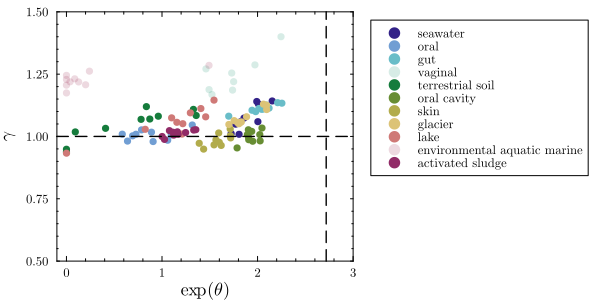

In [14]:
# note that 4 and 13 are for very small systems, let's plot them separately
plot()
for i in 1:length(cdata)
    if inds[i] in [4,13]
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cpal_plot[i], label = classes[inds[i]], alpha = 0.2)
    else
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cpal_plot[i], label = classes[inds[i]])
    end
end
plot!(grid = :none, minorgrid = :none, size = (600,300), xlabel = L"\exp(\theta)", 
        ylabel = L"\gamma", ylims = [0.5,1.5], xlims = [-0.1,3])
plot!([exp(1),exp(1)], [-1,2], linestyle = :dash, color = :black, label = :none)
plot!([-2,3], [1,1], linestyle = :dash, color = :black, label = :none)

In [15]:
markers = [:circle, :rect, :diamond, :star6, :ltriangle, :utriangle, :dtriangle, :pentagon, :star5, :rtriangle, :octagon]

11-element Vector{Symbol}:
 :circle
 :rect
 :diamond
 :star6
 :ltriangle
 :utriangle
 :dtriangle
 :pentagon
 :star5
 :rtriangle
 :octagon

In [16]:
using Plots.Measures

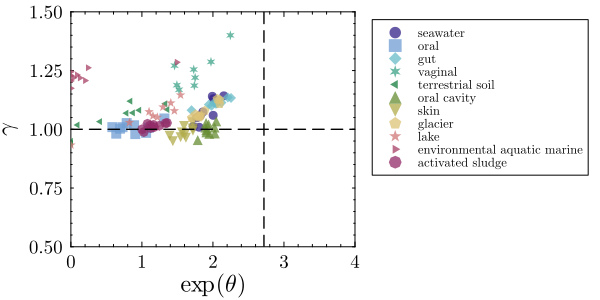

In [17]:
# note that 4 and 13 are for very small systems, let's plot them separately
plot()
for i in 1:length(cdata)
    if inds[i] in [4,13]
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cpal_plot[i], label = classes[inds[i]], marker = markers[i], alpha = 0.75, markersize = 5)
    else
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cpal_plot[i], label = classes[inds[i]], marker = markers[i], markersize = 5, alpha = 0.75)
    end
end
plot!(grid = :none, minorgrid = :none, size = (600,300), xlabel = L"\exp(\theta)", 
        ylabel = L"\gamma", ylims = [0.5,1.5], xlims = [0,4])
plot!([exp(1),exp(1)], [-1,2], linestyle = :dash, color = :black, label = :none)
plot!([-2,10], [1,1], linestyle = :dash, color = :black, label = :none, xlabelfontsize = 16, ylabelfontsize = 16, 
bottom_margin = 3mm, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("calibration-phase-space.pdf")

### Let's make a couple of histograms for each axis

In [18]:
length(cdata)

11

In [19]:
vcat([cdata[x][!,:theta] for x in 1:length(cdata)]...)

110-element Vector{Float64}:
  0.6975821944438831
  0.5444010427764875
  0.5913404292258653
  1.4956765945759418
  0.6000749160157254
  0.5717681730531489
  0.6194690980368854
  0.6948036153078935
  0.7669827735759325
  0.6890249868867928
  0.09245038339575105
 -0.3677240967978902
 -0.24109915782770452
  ⋮
 -1.6062350436351405
 -2.4470615668392055
  0.30293708792891666
  0.07492498233327646
  0.0014785042984051828
  0.2208598067183632
  0.025741755975329964
  0.11649853996772598
  0.1097285605230194
  0.15552298630311864
  0.28656702972930514
  0.14912221331695766

Cleaning: find indices to remove.

In [20]:
all_theta = exp.(vcat([cdata[x][!,:theta] for x in 1:length(cdata)]...));
all_gamma = vcat([cdata[x][!,:gamma] for x in 1:length(cdata)]...);

In [21]:
rm_inds = [];
for i in 1:length(all_theta)
    if all_theta[i] > 3
        push!(rm_inds,i)
    end
end

In [22]:
rm_inds

3-element Vector{Any}:
  4
 39
 40

In [23]:
all_theta[[x ∉ rm_inds for x in 1:length(all_theta)]];

In [24]:
stephist(all_theta[[x ∉ rm_inds for x in 1:length(all_theta)]], xlims = [0,4], fill = true, c = cpal_plot[2], nbins = 20, alpha = 0.5)
plot!(grid = false, minorgrid = false, legend = false)
plot!([0,4],[0,0], color = :black, axis = nothing, framestyle = :none)
savefig("exp-thetas.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/exp-thetas.pdf"

In [25]:
log(mean(all_theta[[x ∉ rm_inds for x in 1:length(all_theta)]]))

0.310165959780625

In [26]:
stephist(all_gamma[[x ∉ rm_inds for x in 1:length(all_gamma)]], xlims = [0.5,1.5], fill = true, c = cpal_plot[end-1], nbins = 10, alpha = 0.5, xflip = true)
plot!(grid = false, minorgrid = false, axis = nothing, framestyle = :none, legend = :none)
plot!([0.5,1.5],[0,0], color = :black)
savefig("gammas.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/gammas.pdf"

In [27]:
mean(all_gamma[[x ∉ rm_inds for x in 1:length(all_gamma)]])

1.0740726362623574

# Making a variant that encode species richness

First, need to find the richnesses of the top 10 ecosystems for each environment of interest.

In [28]:
idxs = [1,2,3,4,5,6,8,9,12,13,14]

11-element Vector{Int64}:
  1
  2
  3
  4
  5
  6
  8
  9
 12
 13
 14

In [38]:
richnesses = []
for i in idxs
    # define temp vector
    r_temp = zeros(10);
    
    # for the group of interest (given by data_ind) split up the samples
    data = groupby(gd1[i], :sample_id)

    # get the top ten microbiomes by size
    sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
    top10inds = sortperm(sizes, rev = true)[1:10];
    
    # cycle over these 10 indices
    for (x,j) in enumerate(top10inds)
        r_temp[x] = length(data[j][!,:count])
    end
    
    push!(richnesses, r_temp)
end   

In [39]:
richnesses

11-element Vector{Any}:
 [398.0, 457.0, 416.0, 232.0, 386.0, 401.0, 365.0, 330.0, 300.0, 326.0]
 [2051.0, 2533.0, 2331.0, 2542.0, 2147.0, 2068.0, 2406.0, 2128.0, 1721.0, 1390.0]
 [2740.0, 3375.0, 3795.0, 3473.0, 3646.0, 5465.0, 3057.0, 2623.0, 3771.0, 3317.0]
 [231.0, 215.0, 196.0, 202.0, 190.0, 177.0, 135.0, 137.0, 74.0, 78.0]
 [1461.0, 2333.0, 1136.0, 1493.0, 1648.0, 1425.0, 1064.0, 1835.0, 2008.0, 1336.0]
 [90.0, 78.0, 89.0, 83.0, 81.0, 89.0, 103.0, 85.0, 91.0, 86.0]
 [573.0, 482.0, 480.0, 553.0, 679.0, 718.0, 318.0, 259.0, 218.0, 532.0]
 [2756.0, 2729.0, 1858.0, 1802.0, 1738.0, 2301.0, 2083.0, 2104.0, 2283.0, 2130.0]
 [2406.0, 4122.0, 1864.0, 1619.0, 1540.0, 1880.0, 1754.0, 1809.0, 1676.0, 2179.0]
 [930.0, 828.0, 793.0, 725.0, 734.0, 661.0, 716.0, 462.0, 600.0, 601.0]
 [7396.0, 8379.0, 8653.0, 7228.0, 8343.0, 7582.0, 7571.0, 7127.0, 6387.0, 7169.0]

In [46]:
max_r = maximum(vcat(richnesses...))

8653.0

In [47]:
r_norms = richnesses ./max_r

11-element Vector{Vector{Float64}}:
 [0.04599560845949382, 0.052814052929619784, 0.04807581185715937, 0.026811510458800415, 0.04460880619438345, 0.04634230902577141, 0.04218190223044031, 0.038137062290535075, 0.03467005662775916, 0.03767479486883162]
 [0.23702762047844678, 0.29273084479371314, 0.2693863399976887, 0.2937709464925459, 0.24812203859932971, 0.23899225702068647, 0.27805385415462847, 0.2459262683462383, 0.1988905581879117, 0.16063792904195076]
 [0.31665318386686697, 0.3900381370622905, 0.43857621634115335, 0.4013636888940252, 0.42135675488269964, 0.631572864902346, 0.3532878770368658, 0.30313186178204093, 0.4358026118109326, 0.38333525944759045]
 [0.02669594360337455, 0.024846873916560732, 0.022651103663469317, 0.023344504796024502, 0.021957702530914135, 0.020455333410377904, 0.015601525482491621, 0.01583265919334335, 0.008551947301513926, 0.009014214723217381]
 [0.1688431757771871, 0.2696174737085404, 0.13128394776378136, 0.17254131515081475, 0.19045417774182363, 0.16468276

In [49]:
r_norms_rounded = [round.(r_norms[x], digits = 2) for x in 1:11]

11-element Vector{Vector{Float64}}:
 [0.05, 0.05, 0.05, 0.03, 0.04, 0.05, 0.04, 0.04, 0.03, 0.04]
 [0.24, 0.29, 0.27, 0.29, 0.25, 0.24, 0.28, 0.25, 0.2, 0.16]
 [0.32, 0.39, 0.44, 0.4, 0.42, 0.63, 0.35, 0.3, 0.44, 0.38]
 [0.03, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.01, 0.01]
 [0.17, 0.27, 0.13, 0.17, 0.19, 0.16, 0.12, 0.21, 0.23, 0.15]
 [0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01]
 [0.07, 0.06, 0.06, 0.06, 0.08, 0.08, 0.04, 0.03, 0.03, 0.06]
 [0.32, 0.32, 0.21, 0.21, 0.2, 0.27, 0.24, 0.24, 0.26, 0.25]
 [0.28, 0.48, 0.22, 0.19, 0.18, 0.22, 0.2, 0.21, 0.19, 0.25]
 [0.11, 0.1, 0.09, 0.08, 0.08, 0.08, 0.08, 0.05, 0.07, 0.07]
 [0.85, 0.97, 1.0, 0.84, 0.96, 0.88, 0.87, 0.82, 0.74, 0.83]

In [50]:
cpal_rich =  [cgrad(:binary)[i] for i in 0.0:1/100:1]

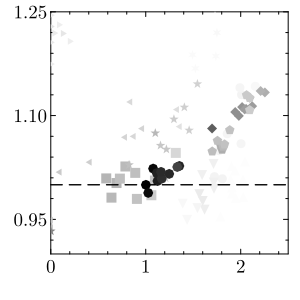

In [66]:
# note that 4 and 13 are for very small systems, let's plot them separately
plot()
for i in 1:length(cdata)
    if inds[i] in [4,13]
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cgrad(:binary)[r_norms_rounded[i]], label = classes[inds[i]], marker = markers[i], markersize = 5)
    else
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cgrad(:binary)[r_norms_rounded[i]], label = classes[inds[i]], marker = markers[i], markersize = 5)
    end
end
plot!(grid = :none, minorgrid = :none, size = (300,300), ylims = [0.9,1.25], xlims = [0,2.5])
plot!([exp(1),exp(1)], [-1,2], linestyle = :dash, color = :black, label = :none)
plot!([-2,10], [1,1], linestyle = :dash, color = :black, label = :none, xlabelfontsize = 16, ylabelfontsize = 16, 
bottom_margin = 3mm, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, legend = :none, xticks = [0,1,2], yticks = [0.95, 1.1, 1.25])
# savefig("richness-phase space.pdf")

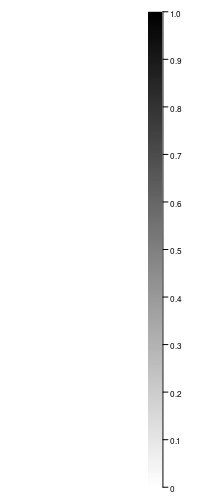

In [68]:
cpal_rich = [cgrad(:binary)[i] for i in 0.0:1/100:1]
grad = cgrad(cpal_rich)

heatmap(
    fill(0.0, 100, 1),
    zcolor = reshape(range(0, 1, length=100), 100, 1),
    c = grad,
    clims = (0, 1),
    xticks = false,
    yticks = false,
    border = :none,
    framestyle = :none,
    colorbar = true,
    size = (220, 500)
)
# savefig("colorbar-richness.pdf")